# 02. v2 prior: 무작위 계산 그래프로 표 만들기

PFN의 성능은 prior가 정합니다. TabPFN v2는 v1의 SCM prior를 크게 바꿔, 실제 표 데이터에 흔한 범주형 feature, 결측값, 무의미한 feature, 계단 모양 관계까지 합성 데이터셋에 넣었습니다(논문 Fig. 2, Methods의 "Details on the causal generative process"). 이 노트북은 그 생성 과정을 작은 예부터 따라가며 직접 만들어 봅니다.

두 가지를 먼저 밝혀 둡니다.

- 논문은 prior 생성 코드를 공개하지 않았습니다(*"The code to generate synthetic pre-training data has not been released with our models"*). Methods에 절차는 있지만 하이퍼파라미터의 분포와 수치는 없습니다. 그래서 이 노트북의 수치는 설명용으로 정한 값이고, 논문에 없는 세부를 정한 곳에는 "여기서 정함"이라고 적었습니다.
- 이 저장소에서 v2를 학습할 때는 공개된 TabICL prior를 씁니다(마지막 절). 이 노트북은 논문의 prior가 어떤 생각으로 만들어졌는지 이해하는 것이 목적입니다.

SCM 자체는 [`02_tabpfn/01_scm_primer`](../02_tabpfn/01_scm_primer.ipynb)에서 다뤘습니다.

다루는 흐름:

1. v1 prior와 무엇이 다른가
2. 그래프 뽑기 — growing network with redirection
3. 노드는 벡터, 간선은 함수
4. 원인 노드의 초기 데이터
5. feature와 target 읽기
6. 후처리 — 휘기, 구간 나누기, 결측값
7. 전부 합쳐 데이터셋 뽑기
8. 이 prior가 가르치는 것
9. 이 저장소가 쓰는 prior
10. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# rng = random number generator(난수 생성기). 모든 무작위 값을 여기서 뽑는다.
rng = np.random.default_rng(0)

## 1. v1 prior와 무엇이 다른가

![TabPFN v2 Figure 2](images/tabpfn_v2_fig2.png)

*그림: 논문 Fig. 2 (Hollmann et al. 2025, [Nature 637:319](https://doi.org/10.1038/s41586-024-08328-6), CC BY 4.0). (a) 데이터셋마다 행 수, feature 수, 노드 수, 그래프 복잡도를 뽑고 그래프를 뽑습니다. (b) 1: 초기 데이터를 그래프에 흘려 보냅니다. 2·3: feature(F)와 target(T) 노드를 골라 그 자리의 값을 읽습니다. 4: 후처리합니다. 아래는 간선의 세 종류(신경망, 나무, 이산화)입니다. (c) 이렇게 만든 데이터셋들입니다.*

v1 prior와 비교하면 다음과 같습니다.

| | v1 (2023) | v2 (2025) | 이 노트북 |
|---|---|---|---|
| 그래프 | 층을 쌓은 MLP 모양, 간선을 무작위로 지움 | scale-free 그래프(growing network with redirection), 여러 조각을 합치기도 함 | 2절 |
| 노드 값 | 숫자 하나 | 벡터 하나 ($\mathbb{R}^d$) | 3절 |
| 간선 | 선형 + 활성화 함수 | 작은 신경망(활성화 함수 12종), 결정 나무, 이산화, 노이즈 | 3절 |
| 원인 노드 입력 | 정규분포 | 정규·균등·혼합, 행끼리 닮게 만들기도 함 | 4절 |
| 범주형 feature | 일부 열을 구간 번호로 바꿈 | 그래프 안에서 이산화한 노드를 그대로 읽음 | 3절, 5절 |
| target | 연속값을 경계로 잘라 클래스로 | 분류: 범주형 노드, 회귀: 연속값 노드 | 5절 |
| 후처리 | 표준화, 이상치 누르기 | Kumaraswamy 휘기, 구간 나누기, 결측값 | 6절 |
| BNN prior | SCM과 반씩 섞음 | 없음 | |

## 2. 그래프 뽑기 — growing network with redirection

v2는 그래프를 growing network with redirection(GNR, Krapivsky & Redner 2001)으로 뽑습니다. 노드를 하나씩 추가하면서 기존 노드에 이어 붙이는 방법입니다.

1. 노드 0 하나로 시작합니다.
2. 새 노드 $t$가 올 때마다 기존 노드 하나를 고르게 고릅니다.
3. 확률 $P$로 "방향을 바꿉니다(redirection)". 고른 노드 대신, 고른 노드가 이어 붙었던 노드에 붙습니다.
4. 새 노드와 붙은 노드를 간선으로 잇습니다.

3번 때문에 이미 많이 붙은 노드가 더 자주 선택됩니다. 많이 붙은 노드일수록 "고른 노드가 이어 붙었던 노드"로 자주 등장하기 때문입니다. 그래서 간선이 몇몇 노드(hub)에 몰리는 scale-free 그래프가 됩니다. 노드 수 $N$은 로그 균등분포에서, $P$는 감마분포에서 뽑습니다(논문).

간선 방향은 논문에 없어서 여기서 정했습니다. 새 노드 → 붙은 노드, 즉 나중에 생긴 노드를 원인으로 둡니다. 그러면 원인 노드(부모가 없는 노드)가 여럿 생기고, hub는 원인이 많이 모이는 노드가 됩니다.

노드 6개로 먼저 따라가 봅니다.

In [3]:
def sample_gnr_graph(n_nodes, p_redirect, rng):
    attached_to = {0: None}  # attached_to[t] = 새 노드 t가 이어 붙은 기존 노드
    steps = []
    for t in range(1, n_nodes):
        picked = int(rng.integers(0, t))  # 2. 기존 노드 하나를 고르게 고른다
        can_redirect = attached_to[picked] is not None  # 노드 0은 붙은 노드가 없다
        redirected = can_redirect and rng.random() < p_redirect  # 3. 확률 P로 방향을 바꾼다
        if redirected:
            attach = attached_to[picked]
        else:
            attach = picked
        attached_to[t] = attach  # 4. t → attach 간선
        steps.append(
            {"새 노드": t, "고른 노드": picked, "방향 바꿈": redirected, "붙은 노드": attach}
        )
    # 간선 t → attached_to[t]: t가 원인, attached_to[t]가 결과
    parents = {u: [t for t in range(n_nodes) if attached_to[t] == u] for u in range(n_nodes)}
    return parents, steps


parents, steps = sample_gnr_graph(6, p_redirect=0.5, rng=np.random.default_rng(3))
display(pd.DataFrame(steps))
display(pd.DataFrame({"부모(원인)": {u: pa for u, pa in parents.items()}}))

,새 노드,고른 노드,방향 바꿈,붙은 노드
0,1,0,False,0
1,2,1,True,0
2,3,0,False,0
3,4,0,False,0
4,5,4,False,4


,부모(원인)
0,"[1, 2, 3, 4]"
1,[]
2,[]
3,[]
4,[5]
5,[]


그래프를 그릴 때는 원인 노드를 왼쪽에, 결과 쪽 노드를 오른쪽에 둡니다. 노드 0은 모든 간선이 결국 모이는 곳이라 맨 오른쪽입니다.

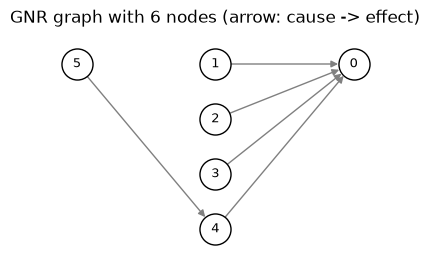

In [4]:
def layout(parents):
    # 노드 0에서 거슬러 올라간 거리를 x 위치로 쓴다 (원인일수록 왼쪽)
    child_of = {t: u for u, pa in parents.items() for t in pa}
    depth = {}
    for node in sorted(parents):
        d, cur = 0, node
        while cur in child_of:
            cur, d = child_of[cur], d + 1
        depth[node] = d
    pos, used = {}, {}
    for node in sorted(parents):
        level = depth[node]
        pos[node] = (-level, -used.get(level, 0))
        used[level] = used.get(level, 0) + 1
    return pos


def draw_graph(ax, parents, colors=None, labels=None, node_size=500, title=None):
    colors = colors or {}
    labels = labels or {node: str(node) for node in parents}
    pos = layout(parents)
    shrink = np.sqrt(node_size) / 2
    for child, pa in parents.items():
        for parent in pa:
            ax.annotate(
                "",
                xy=pos[child],
                xytext=pos[parent],
                arrowprops=dict(
                    arrowstyle="-|>", color="gray", lw=1, shrinkA=shrink, shrinkB=shrink
                ),
            )
    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=node_size, color=colors.get(node, "white"), edgecolor="black", zorder=3)
        ax.text(x, y, labels.get(node, ""), ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title or "")
    ax.margins(0.2)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(5, 3))
draw_graph(ax, parents, title="GNR graph with 6 nodes (arrow: cause -> effect)")
plt.show()

간선 수는 항상 노드 수 − 1이고, 노드마다 자식(결과)이 하나뿐인 나무 모양입니다. 논문은 $P$가 작을수록 간선이 많은 조밀한 그래프가 된다고 적었는데, 원래 GNR은 간선 수가 일정하므로 논문 구현은 GNR을 어떤 식으로든 바꿨을 것입니다. 그 방법은 알 수 없어서, 여기서는 원래 GNR을 쓰고 $P$가 hub의 크기를 바꾸는 것만 봅니다. 노드 200개짜리 그래프에서 부모 수(들어오는 간선 수)를 셉니다.

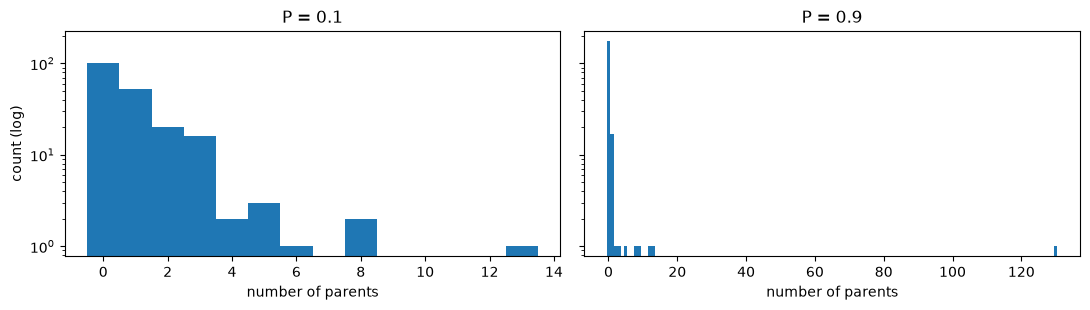

,P,원인 노드(부모 0개) 비율,가장 큰 hub의 부모 수
0,0.1,51%,13
1,0.9,88%,130


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
rows = []
for ax, p in zip(axes, [0.1, 0.9], strict=True):
    big, _ = sample_gnr_graph(200, p_redirect=p, rng=np.random.default_rng(0))
    n_parents = np.array([len(pa) for pa in big.values()])
    ax.hist(n_parents, bins=np.arange(-0.5, n_parents.max() + 1.5), color="C0")
    ax.set_yscale("log")
    ax.set_xlabel("number of parents")
    ax.set_title(f"P = {p}")
    rows.append(
        {
            "P": p,
            "원인 노드(부모 0개) 비율": f"{np.mean(n_parents == 0):.0%}",
            "가장 큰 hub의 부모 수": int(n_parents.max()),
        }
    )
axes[0].set_ylabel("count (log)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

$P$가 크면 방향 바꾸기가 잦아서 소수의 hub에 원인이 몰립니다. 어느 쪽이든 노드의 절반 이상이 원인 노드입니다.

논문은 그래프 하나를 쓰거나, 따로 뽑은 그래프 여러 개를 합쳐 쓴다고 적었습니다. 합친 그래프에서 target과 다른 조각에 있는 feature는 target과 아무 관계가 없습니다. 실제 표에 흔한 무의미한 feature를 이렇게 만듭니다.

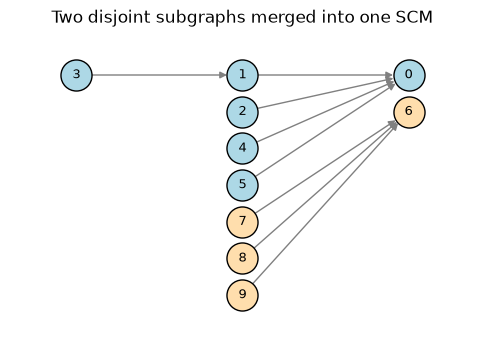

In [6]:
def merge_graphs(graphs):
    # 조각마다 노드 번호를 겹치지 않게 밀어서 합친다
    merged, offset, component = {}, 0, {}
    for k, g in enumerate(graphs):
        for u, pa in g.items():
            merged[u + offset] = [t + offset for t in pa]
            component[u + offset] = k
        offset += len(g)
    return merged, component


g1, _ = sample_gnr_graph(6, 0.5, np.random.default_rng(1))
g2, _ = sample_gnr_graph(4, 0.5, np.random.default_rng(2))
merged, component = merge_graphs([g1, g2])

fig, ax = plt.subplots(figsize=(6, 4))
draw_graph(
    ax,
    merged,
    colors={u: ("lightblue" if k == 0 else "navajowhite") for u, k in component.items()},
    title="Two disjoint subgraphs merged into one SCM",
)
plt.show()

## 3. 노드는 벡터, 간선은 함수

v1에서는 노드 값이 숫자 하나였습니다. v2에서는 노드 값이 길이 $d$인 벡터입니다. 간선마다 부모의 벡터를 자식의 벡터로 바꾸는 함수가 하나씩 있고, 함수의 종류는 논문 Fig. 2b 아래의 세 가지입니다.

- **작은 신경망**: $\sigma(Wx + b)$. $W$는 Xavier 초기화로 뽑고, 활성화 함수 $\sigma$는 identity, log, sigmoid, 절댓값, sin, tanh, 순위(rank), 제곱, 거듭제곱, smooth ReLU, 계단, 나머지(modulo) 중 하나입니다.
- **결정 나무**: 입력 벡터의 좌표 몇 개에 문턱값을 두고, 어느 잎에 떨어지느냐로 출력 벡터를 정합니다. 규칙 기반의 계단 모양 관계를 만듭니다.
- **이산화**: 벡터를 미리 뽑아 둔 대표 벡터 $K$개 중 가장 가까운 것의 번호로 바꿉니다. 이 번호가 범주형 feature가 됩니다. 그래프 안에서 계속 쓰려면 번호마다 따로 뽑은 임베딩 벡터로 바꿔 흘려 보냅니다.

모든 간선은 마지막에 정규분포 노이즈 $\mathcal{N}(0, \sigma^2 I)$를 더합니다. 행 하나($d = 3$)로 각 함수를 따라가 봅니다. 먼저 활성화 함수들입니다.

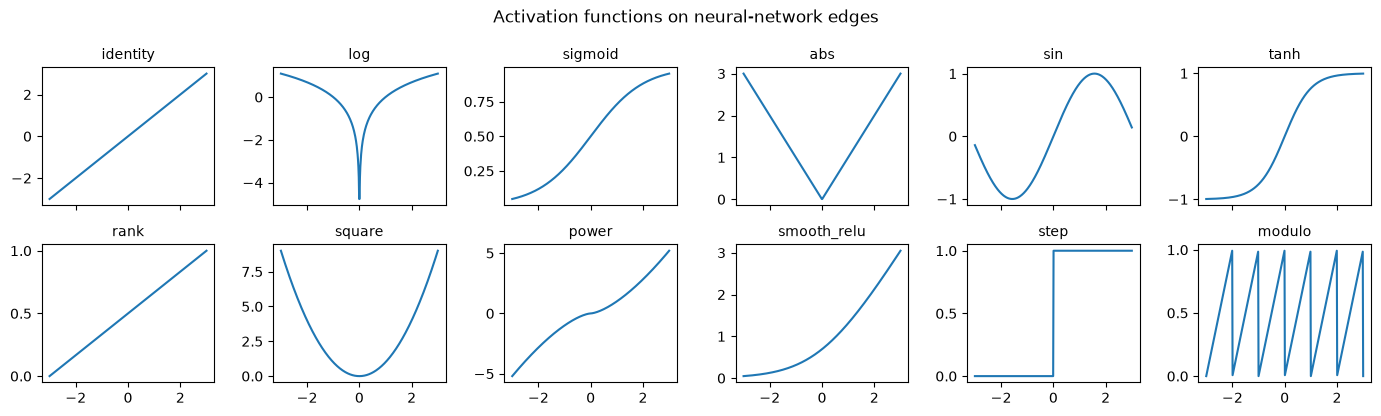

In [7]:
def rank(v):
    # 순위 변환: 같은 좌표의 행들 사이에서 몇 번째로 작은지 (0~1)
    return np.argsort(np.argsort(v, axis=0), axis=0) / max(len(v) - 1, 1)


ACTIVATIONS = {
    "identity": lambda v: v,
    "log": lambda v: np.log(np.abs(v) + 1e-3),
    "sigmoid": lambda v: 1 / (1 + np.exp(-v)),
    "abs": np.abs,
    "sin": np.sin,
    "tanh": np.tanh,
    "rank": rank,
    "square": np.square,
    "power": lambda v: np.sign(v) * np.abs(v) ** 1.5,
    "smooth_relu": lambda v: np.log1p(np.exp(v)),
    "step": lambda v: (v > 0).astype(float),
    "modulo": lambda v: np.mod(v, 1.0),
}

grid = np.linspace(-3, 3, 400)[:, None]
fig, axes = plt.subplots(2, 6, figsize=(14, 4.2), sharex=True)
for ax, (name, f) in zip(axes.flat, ACTIVATIONS.items(), strict=True):
    ax.plot(grid[:, 0], f(grid)[:, 0], color="C0")
    ax.set_title(name, fontsize=10)
fig.suptitle("Activation functions on neural-network edges")
plt.tight_layout()
plt.show()

계단과 나머지 함수는 매끄럽지 않은 관계를, 순위 함수는 값의 크기 대신 순서만 남기는 관계를 만듭니다. v1의 활성화 함수 3종(tanh, identity, ReLU)보다 훨씬 다양합니다.

이제 행 하나의 부모 벡터 $x = [0.5, -1.0, 0.3]$이 세 종류의 간선을 지나는 과정을 단계별로 봅니다. **신경망 간선**부터입니다.

In [8]:
d = 3
x = np.array([[0.5, -1.0, 0.3]])  # 부모 노드의 벡터 (행 1개)

edge_rng = np.random.default_rng(7)
limit = np.sqrt(6 / (d + d))  # Xavier 균등 초기화의 범위
W = edge_rng.uniform(-limit, limit, (d, d))
b = edge_rng.normal(0, 0.5, d)

# 1단계: 선형 변환
linear = x @ W.T + b
# 2단계: 활성화 함수 (여기서는 sin)
out = ACTIVATIONS["sin"](linear)

display(
    pd.DataFrame(
        {"부모 x": x[0], "Wx + b": linear[0], "sin(Wx + b)": out[0]},
        index=[f"좌표 {i}" for i in range(d)],
    ).round(3)
)

,부모 x,Wx + b,sin(Wx + b)
좌표 0,0.5,-0.814,-0.727
좌표 1,-1.0,0.594,0.560
좌표 2,0.3,-0.781,-0.704


**결정 나무 간선**은 깊이 2짜리 나무로 봅니다. 뿌리에서 좌표 하나를 문턱값과 비교해 왼쪽·오른쪽으로 가고, 거기서 다른 좌표로 한 번 더 갈라 잎 4개 중 하나에 도착합니다. 잎마다 출력 벡터가 정해져 있습니다. 갈림길이 보는 좌표와 문턱값, 잎의 출력은 간선마다 무작위로 뽑습니다.

In [9]:
split_dims = [0, 2, 1]  # 뿌리, 왼쪽 갈림길, 오른쪽 갈림길이 보는 좌표
thresholds = [0.2, 0.0, -0.5]
leaves = np.round(edge_rng.normal(0, 1, (4, d)), 2)  # 잎 4개의 출력 벡터

# 1단계: 뿌리 — 좌표 0이 0.2보다 큰가?
go_right = x[0, split_dims[0]] > thresholds[0]
# 2단계: 오른쪽이면 좌표 1, 왼쪽이면 좌표 2를 본다
if go_right:
    second = x[0, split_dims[2]] > thresholds[2]
else:
    second = x[0, split_dims[1]] > thresholds[1]
# 3단계: 도착한 잎의 출력 벡터
leaf = 2 * int(go_right) + int(second)

print(f"뿌리: x[0] = {x[0, 0]} > {thresholds[0]} ? {go_right}")
print(f"둘째 갈림길: x[1] = {x[0, 1]} > {thresholds[2]} ? {second}")
print(f"도착한 잎: {leaf}, 출력 = {leaves[leaf]}")

뿌리: x[0] = 0.5 > 0.2 ? True
둘째 갈림길: x[1] = -1.0 > -0.5 ? False
도착한 잎: 2, 출력 = [-1.9  -1.29 -1.84]


**이산화**는 대표 벡터와의 거리를 재서 가장 가까운 것의 번호를 고릅니다. 대표 벡터 수 $K$는 반올림한 감마분포에 2를 더해 뽑습니다(최소 2개, 논문). 여기서는 $K = 3$입니다.

In [10]:
K = 3
prototypes = np.round(edge_rng.normal(0, 1, (K, d)), 2)  # 대표 벡터 p_1..p_K
embeddings = np.round(edge_rng.normal(0, 1, (K, d)), 2)  # 번호마다 그래프 안에서 쓸 벡터 p'_1..p'_K

# 1단계: 대표 벡터마다 거리
distance = np.sqrt(((x[0] - prototypes) ** 2).sum(axis=1))
# 2단계: 가장 가까운 대표 벡터의 번호 = 범주형 값
category = int(distance.argmin())
# 3단계: 그 번호의 임베딩 벡터를 자식 노드로 흘려 보낸다

display(
    pd.DataFrame(
        {"대표 벡터": [str(p) for p in prototypes], "x와의 거리": distance.round(3)},
        index=[f"범주 {k}" for k in range(K)],
    )
)
print(f"범주형 값 = {category}, 흘려 보내는 벡터 = {embeddings[category]}")

,대표 벡터,x와의 거리
범주 0,[ 0.16 -0.19 -2.52],2.954
범주 1,[-0.54 -0.05 0.11],1.421
범주 2,[-1.53 -0.48 -0.98],2.456


범주형 값 = 1, 흘려 보내는 벡터 = [-0.03  0.88 -0.58]


부모가 여럿인 노드에서 간선 출력을 어떻게 합치는지는 논문에 없습니다. 여기서는 간선 출력을 더한 뒤 노이즈를 더하고, 값의 크기가 깊이에 따라 커지거나 작아지지 않도록 좌표마다 행들 사이에서 표준화합니다(여기서 정함). 또 이산화는 간선 대신 노드에 붙였습니다. 부모가 여럿이어도 범주형 값이 하나로 정해지게 하기 위해서입니다(여기서 정함).

In [11]:
def make_nn_edge(d, rng):
    limit = np.sqrt(6 / (d + d))
    W = rng.uniform(-limit, limit, (d, d))
    b = rng.normal(0, 0.5, d)
    act = ACTIVATIONS[rng.choice(list(ACTIVATIONS))]
    return lambda v: act(v @ W.T + b)


def make_tree_edge(d, rng):
    dims = rng.integers(0, d, size=3)
    cuts = rng.normal(0, 0.5, size=3)
    leaf_values = rng.normal(0, 1, size=(4, d))

    def edge(v):
        go_right = v[:, dims[0]] > cuts[0]
        second = np.where(go_right, v[:, dims[2]] > cuts[2], v[:, dims[1]] > cuts[1])
        return leaf_values[2 * go_right + second]

    return edge


def standardize(v):
    return (v - v.mean(axis=0)) / (v.std(axis=0) + 1e-8)

## 4. 원인 노드의 초기 데이터

원인 노드(부모가 없는 노드)에는 행마다 초기 데이터 $\epsilon$을 넣습니다. 세 가지 방식 중 하나입니다(논문).

- 정규: $\epsilon \sim \mathcal{N}(0, \sigma_\epsilon^2)$
- 균등: $\epsilon \sim U(-a, a)$
- 혼합: 원인 노드마다 정규와 균등 중 하나를 고름

일부 데이터셋에서는 행끼리 서로 닮게 만듭니다. 행의 일부($\rho n$개)를 "원형(prototype)" $x^*_1, \dots, x^*_M$으로 먼저 뽑고, 모든 행을 원형들의 가중 평균으로 만듭니다.

$$
x_i = \sum_{j=1}^{M} \alpha_{ij}\, x^*_j, \qquad \sum_j \alpha_{ij} = 1
$$

온도 $\beta$가 크면 가중치가 고르게 퍼지고, 작으면 원형 몇 개에 몰립니다. 논문은 가중치를 "Multinomial($\beta$)"에서 뽑는다고만 적어서, 여기서는 표준정규 난수를 $\beta$로 나눠 softmax한 값을 가중치로 씁니다(여기서 정함). 원형 3개, 행 2개로 가중치를 봅니다.

In [12]:
def prototype_weights(n_rows, n_prototypes, beta, rng):
    logits = rng.standard_normal((n_rows, n_prototypes)) / beta
    w = np.exp(logits - logits.max(axis=1, keepdims=True))
    return w / w.sum(axis=1, keepdims=True)  # 행마다 합이 1


for beta in [5.0, 0.2]:
    w = prototype_weights(2, 3, beta, np.random.default_rng(0))
    print(f"β = {beta}")
    display(
        pd.DataFrame(w, columns=["원형 1", "원형 2", "원형 3"], index=["행 1", "행 2"]).round(2)
    )

β = 5.0


,원형 1,원형 2,원형 3
행 1,0.33,0.31,0.36
행 2,0.34,0.30,0.36


β = 0.2


,원형 1,원형 2,원형 3
행 1,0.07,0.02,0.91
행 2,0.22,0.01,0.78


$\beta = 5$에서는 행마다 세 원형을 고르게 섞고, $\beta = 0.2$에서는 원형 하나를 거의 그대로 가져옵니다. 원인 노드 하나(2차원)의 초기 데이터 500행으로 차이를 그려 봅니다.

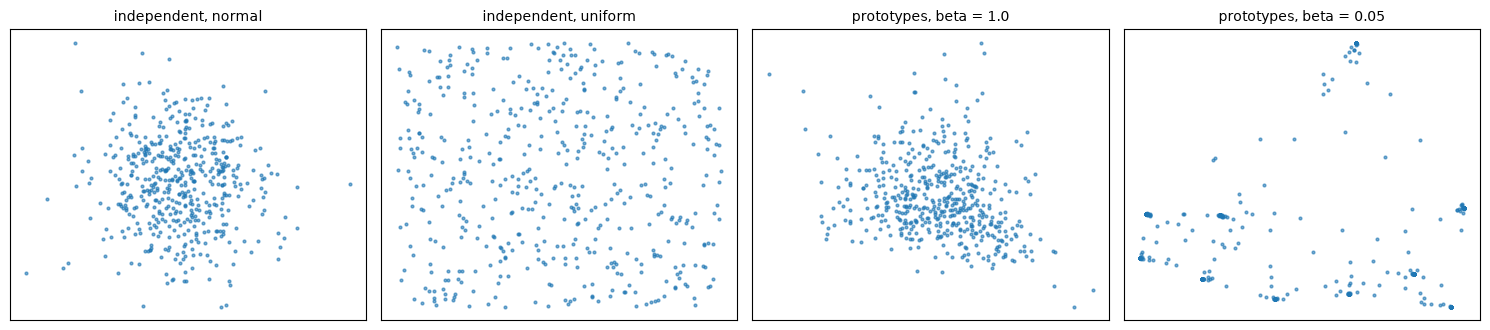

In [13]:
def sample_init(n_rows, width, rng, mode="normal", prototype_frac=None, beta=1.0):
    # 원인 노드들의 초기 데이터 (n_rows, width)
    def draw(n):
        if mode == "normal":
            return rng.normal(0, 1, (n, width))
        if mode == "uniform":
            return rng.uniform(-1.7, 1.7, (n, width))
        # mixed: 열마다 정규 또는 균등
        use_normal = rng.random(width) < 0.5
        return np.where(
            use_normal, rng.normal(0, 1, (n, width)), rng.uniform(-1.7, 1.7, (n, width))
        )

    if prototype_frac is None:
        return draw(n_rows)
    n_proto = max(2, round(prototype_frac * n_rows))
    prototypes = draw(n_proto)
    weights = prototype_weights(n_rows, n_proto, beta, rng)
    return weights @ prototypes


init_rng = np.random.default_rng(1)
settings = {
    "independent, normal": dict(mode="normal"),
    "independent, uniform": dict(mode="uniform"),
    "prototypes, beta = 1.0": dict(mode="normal", prototype_frac=0.02, beta=1.0),
    "prototypes, beta = 0.05": dict(mode="normal", prototype_frac=0.02, beta=0.05),
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (title, kw) in zip(axes, settings.items(), strict=True):
    eps = standardize(sample_init(500, 2, init_rng, **kw))
    ax.scatter(eps[:, 0], eps[:, 1], s=4, alpha=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

원형을 쓰고 $\beta$가 작으면 행들이 원형 10개 근처에 덩어리로 모입니다. 같은 고객이 여러 번 나오거나, 비슷한 실험 조건이 반복되는 표처럼 행이 서로 독립이 아닌 데이터를 흉내 냅니다.

## 5. feature와 target 읽기

그래프의 모든 노드를 계산한 뒤, feature 노드와 target 노드를 무작위로 골라 그 자리의 값을 읽습니다(논문 Fig. 2b의 2·3단계). 노드 값은 벡터이므로 연속값 노드는 좌표 하나를 읽고(여기서 정함), 이산화한 노드는 범주 번호를 읽습니다.

- **분류**: 범주가 10개 이하인 범주형 노드를 target으로 고릅니다. 그래서 v2는 클래스를 10개까지만 직접 예측합니다.
- **회귀**: 후처리하지 않은 연속값 노드를 target으로 고릅니다.

[`01_scm_primer`](../02_tabpfn/01_scm_primer.ipynb) 6절과 같은 방식으로 두 단계로 봅니다. 노드 5개, $d = 2$, 행 5개짜리 그래프에서 노드 3을 범주형 노드로 둡니다.

In [14]:
def propagate(parents, n_rows, d, rng, categorical=(), init_kw=None, tree_prob=0.25, noise_std=0.1):
    # 모든 노드의 벡터를 계산한다. 간선은 새 노드 → 기존 노드 방향이라 번호가 큰 노드부터 계산한다.
    order = sorted(parents, reverse=True)
    roots = [u for u in order if not parents[u]]
    init = standardize(sample_init(n_rows, len(roots) * d, rng, **(init_kw or {})))
    values, categories = {}, {}
    for u in order:
        if not parents[u]:
            k = roots.index(u)
            values[u] = init[:, k * d : (k + 1) * d]  # 원인 노드: 초기 데이터
        else:
            total = np.zeros((n_rows, d))
            for parent in parents[u]:
                edge = make_tree_edge(d, rng) if rng.random() < tree_prob else make_nn_edge(d, rng)
                total += edge(values[parent])  # 간선마다 함수를 지나 더한다
            values[u] = standardize(total + rng.normal(0, noise_std, (n_rows, d)))
        if u in categorical:
            # 이산화: 가장 가까운 대표 벡터의 번호 → 범주형 값
            n_cat = categorical[u]
            protos = values[u][
                rng.choice(n_rows, size=n_cat, replace=False)
            ]  # 대표 벡터는 실제 값 중에서
            dist = ((values[u][:, None, :] - protos[None]) ** 2).sum(-1)
            categories[u] = dist.argmin(axis=1)
            # 번호마다 뽑은 임베딩 벡터를 자식으로 흘려 보낸다
            embeddings = rng.normal(0, 1, (n_cat, d))
            values[u] = embeddings[categories[u]]
    return values, categories


tiny_parents = {0: [1, 3], 1: [2], 2: [], 3: [4], 4: []}
vals, cats = propagate(
    tiny_parents, n_rows=5, d=2, rng=np.random.default_rng(4), categorical={3: 3}
)

# 1단계: 모든 노드의 값 (벡터)
all_nodes = pd.DataFrame(
    {
        f"노드 {u}": ["[" + ", ".join(f"{a:.2f}" for a in row) + "]" for row in vals[u]]
        for u in sorted(vals)
    }
)
all_nodes["노드 3의 범주"] = cats[3]
display(all_nodes)

,노드 0,노드 1,노드 2,노드 3,노드 4,노드 3의 범주
0,"[1.41, 1.07]","[0.24, -0.83]","[1.69, -0.08]","[-0.71, -0.61]","[0.54, -1.14]",2
1,"[-0.68, 0.59]","[0.53, -0.68]","[-0.49, -0.55]","[0.95, -0.20]","[-0.65, -0.76]",0
2,"[-0.84, -1.49]","[-1.89, 1.88]","[0.33, 0.75]","[0.75, 0.85]","[-0.61, -0.21]",1
3,"[1.01, -0.89]","[1.04, 0.15]","[-1.32, 1.37]","[-0.71, -0.61]","[1.71, 0.39]",2
4,"[-0.91, 0.71]","[0.08, -0.52]","[-0.21, -1.49]","[0.95, -0.20]","[-0.99, 1.71]",0


노드 3은 범주형 노드입니다. 계산한 벡터를 가장 가까운 대표 벡터의 번호(범주)로 바꾸고, 그 번호의 임베딩 벡터를 자식인 노드 0으로 흘려 보냅니다. 표의 노드 3 열이 흘려 보낸 임베딩 벡터입니다. 같은 범주인 행은 같은 벡터를 가집니다.

**2단계: 열 몇 개만 남깁니다.** 노드 3을 분류 target으로, 노드 2와 노드 0을 feature로 고르고 각각 좌표 0을 읽습니다. 노드 1과 4는 버립니다.

,"x1 (노드 2, 좌표 0)","x2 (노드 0, 좌표 0)",y (노드 3의 범주)
0,1.69,1.41,2
1,-0.49,-0.68,0
2,0.33,-0.84,1
3,-1.32,1.01,2
4,-0.21,-0.91,0


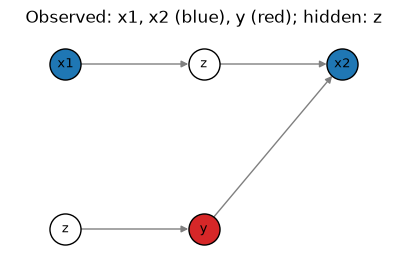

In [15]:
dataset = pd.DataFrame(
    {
        "x1 (노드 2, 좌표 0)": vals[2][:, 0].round(2),
        "x2 (노드 0, 좌표 0)": vals[0][:, 0].round(2),
        "y (노드 3의 범주)": cats[3],
    }
)
display(dataset)

fig, ax = plt.subplots(figsize=(5, 3))
draw_graph(
    ax,
    tiny_parents,
    colors={2: "C0", 0: "C0", 3: "C3"},
    labels={0: "x2", 1: "z", 2: "x1", 3: "y", 4: "z"},
    title="Observed: x1, x2 (blue), y (red); hidden: z",
)
plt.show()

x1(노드 2)은 노드 1을 거쳐 x2(노드 0)의 원인이고, y(노드 3)도 x2의 원인입니다. 그래서 x1과 y는 직접 관계가 없지만, x2는 두 원인의 결과(collider)라 y를 예측하는 데 쓸모가 있습니다. feature가 target의 원인일 수도, 결과일 수도, 무관할 수도 있다는 점은 v1과 같습니다.

## 6. 후처리 — 휘기, 구간 나누기, 결측값

마지막으로 feature를 실제 표처럼 다듬습니다(논문 Methods "Post-processing"). 데이터셋마다 다음 중 하나 이상을 무작위로 적용합니다.

1. **Kumaraswamy 휘기**: feature를 $[0, 1]$로 옮긴 뒤 Kumaraswamy 분포의 누적분포함수 $F(x) = 1 - (1 - x^a)^b$로 휩니다. $a, b$에 따라 한쪽으로 몰리거나 양끝으로 퍼집니다.
2. **구간 나누기**: 연속값 feature를 구간 $K$개의 번호로 바꿉니다. 경계 $K + 1$개는 그 feature가 실제로 가진 값들 중에서 뽑습니다. 등급, 나이대처럼 구간으로 기록된 열을 흉내 냅니다.
3. **결측값**: 셀마다 확률 $\rho_{miss}$로 값을 지웁니다. 값과 무관하게 지우는 방식(MCAR, missing completely at random)입니다.

먼저 휘기입니다.

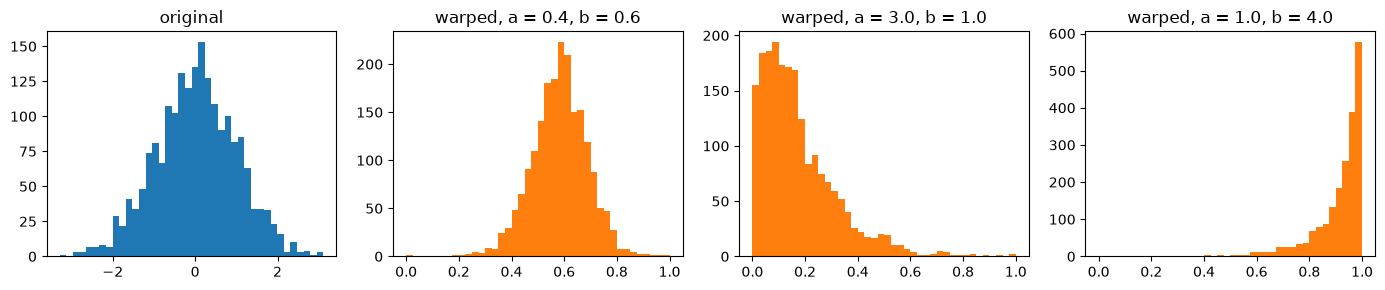

In [16]:
def kumaraswamy_warp(v, a, b):
    v01 = (v - v.min()) / (v.max() - v.min())  # [0, 1]로 옮긴다
    return 1 - (1 - v01**a) ** b


feature = np.random.default_rng(5).normal(0, 1, 2000)
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].hist(feature, bins=40, color="C0")
axes[0].set_title("original")
for ax, (a, b) in zip(axes[1:], [(0.4, 0.6), (3.0, 1.0), (1.0, 4.0)], strict=True):
    ax.hist(kumaraswamy_warp(feature, a, b), bins=40, color="C1")
    ax.set_title(f"warped, a = {a}, b = {b}")
plt.tight_layout()
plt.show()

같은 정규분포 feature가 양끝에 몰린 분포, 오른쪽에 몰린 분포, 왼쪽에 몰린 분포로 바뀝니다. 실제 표에는 정규분포에서 먼 열이 많으므로, 모델이 이런 열을 학습 때 미리 보게 합니다.

**구간 나누기**는 값 8개짜리 feature로 따라갑니다. $K = 3$이면 경계 4개를 feature 값들 중에서 뽑고, 안쪽 경계 2개로 구간 번호를 정합니다.

In [17]:
values8 = np.array([0.31, -1.20, 0.75, 2.10, -0.42, 1.05, -0.05, 0.60])
K = 3

# 1단계: feature가 가진 값들 중에서 경계 K + 1 = 4개를 뽑아 정렬한다
edges = np.sort(np.random.default_rng(2).choice(values8, size=K + 1, replace=False))
# 2단계: 안쪽 경계로 구간 번호를 정한다 (바깥 경계 밖의 값은 맨 앞·맨 뒤 구간)
bucket = np.digitize(values8, edges[1:-1])

print("경계:", edges)
display(pd.DataFrame({"원래 값": values8, "구간 번호": bucket}))

경계: [-1.2  -0.42  0.31  0.75]


,원래 값,구간 번호
0,0.31,2
1,-1.20,0
2,0.75,2
3,2.10,2
4,-0.42,1
5,1.05,2
6,-0.05,1
7,0.60,2


**결측값**은 표 전체에서 셀을 고르게 지웁니다.

In [18]:
table = pd.DataFrame(
    np.random.default_rng(6).normal(0, 1, (6, 4)).round(2), columns=["x1", "x2", "x3", "x4"]
)
rho_miss = 0.2
missing = np.random.default_rng(7).random(table.shape) < rho_miss  # 셀마다 확률 0.2로 지운다
display(table.mask(missing))
print(f"지운 셀: {missing.sum()}개 / {missing.size}개")

,x1,x2,x3,x4
0,1.05,1.78,-2.55,-0.14
1,1.01,1.35,NaN,1.50
2,0.29,0.55,0.18,-1.07
3,-0.85,0.38,-0.58,1.27
4,1.29,1.80,-0.03,1.38
5,-0.91,NaN,0.08,NaN


지운 셀: 3개 / 24개


v2 모델은 이 빈 칸을 평균으로 채우고 빈 칸 표시를 붙여 입력합니다([`01_two_way_attention_primer`](01_two_way_attention_primer.ipynb) 2절). 학습 때 결측값이 있는 데이터셋을 많이 봤으므로, 빈 칸 표시를 보고 "값이 없을 때 어떻게 예측할지"를 스스로 배웁니다. v1은 prior에 결측값이 없었고 테스트 때 0으로 바꿨을 뿐이라 결측값이 있는 데이터셋에서 약했습니다.

## 7. 전부 합쳐 데이터셋 뽑기

2~6절을 합쳐 데이터셋 하나를 뽑는 함수를 만듭니다. 하이퍼파라미터는 데이터셋마다 새로 뽑습니다. 논문은 이 하이퍼파라미터들에도 분포를 두고 섞었으므로, PFN이 근사하는 PPD는 하이퍼파라미터에 대해서도 적분한 것이 됩니다(Methods). 분포의 수치는 설명용으로 정했습니다.

In [19]:
def sample_dataset(rng, task="classification", n_rows=300, n_features=4):
    # 1) 하이퍼파라미터 (설명용 분포)
    d = int(rng.integers(2, 5))  # 노드 벡터 길이
    n_nodes = int(np.exp(rng.uniform(np.log(n_features + 4), np.log(40))))  # 로그 균등
    p_redirect = min(rng.gamma(2.0, 0.2), 0.95)  # 감마분포
    init_kw = {"mode": rng.choice(["normal", "uniform", "mixed"])}
    if rng.random() < 0.3:  # 행끼리 닮게 만들기
        init_kw |= {
            "prototype_frac": rng.uniform(0.01, 0.1),
            "beta": np.exp(rng.uniform(np.log(0.05), np.log(2))),
        }

    # 2) 그래프: 하나 또는 두 조각을 합친 것
    if rng.random() < 0.3:
        split = int(rng.integers(2, n_nodes - 1))
        g1, _ = sample_gnr_graph(split, p_redirect, rng)
        g2, _ = sample_gnr_graph(n_nodes - split, p_redirect, rng)
        parents, _ = merge_graphs([g1, g2])
    else:
        parents, _ = sample_gnr_graph(n_nodes, p_redirect, rng)

    # 3) target 노드와 feature 노드를 고른다
    nodes = rng.permutation(n_nodes)
    target, feature_nodes = int(nodes[0]), [int(u) for u in nodes[1 : n_features + 1]]
    categorical = {}
    if task == "classification":
        categorical[target] = int(rng.integers(2, 11))  # 클래스 2~10개
    for u in feature_nodes:
        if rng.random() < 0.2:  # 범주형 feature
            categorical[u] = 2 + round(rng.gamma(1.5, 1.5))

    # 4) 초기 데이터를 흘려 보낸다
    values, categories = propagate(
        parents, n_rows, d, rng, categorical=categorical, init_kw=init_kw
    )

    # 5) 값을 읽는다: 범주형 노드는 범주 번호, 연속값 노드는 좌표 하나
    def read(u):
        return categories[u].astype(float) if u in categories else values[u][:, rng.integers(d)]

    x = np.stack([read(u) for u in feature_nodes], axis=1)
    y = categories[target] if task == "classification" else values[target][:, 0]

    # 6) 후처리: 연속값 feature만 휘거나 구간으로 나누고, 마지막에 결측값
    for j, u in enumerate(feature_nodes):
        if u in categories:
            continue
        r = rng.random()
        if r < 0.2:
            x[:, j] = kumaraswamy_warp(x[:, j], *np.exp(rng.uniform(np.log(0.3), np.log(3), 2)))
        elif r < 0.3:
            k = int(rng.integers(2, 8))
            cut = np.sort(rng.choice(x[:, j], size=k + 1, replace=False))
            x[:, j] = np.digitize(x[:, j], cut[1:-1])
    if rng.random() < 0.3:
        x[rng.random(x.shape) < rng.uniform(0, 0.2)] = np.nan
    return x, y

분류 데이터셋을 여러 개 뽑아 앞의 두 feature로 그립니다. v1 walkthrough처럼 feature로 클래스를 꽤 맞힐 수 있는 데이터셋(kNN 정확도가 가장 큰 클래스의 비율보다 0.2 이상 높음) 중에서, 앞의 두 feature가 연속값인 것만 골라 보여 줍니다. 회귀 데이터셋은 feature 하나와 target을 그립니다.

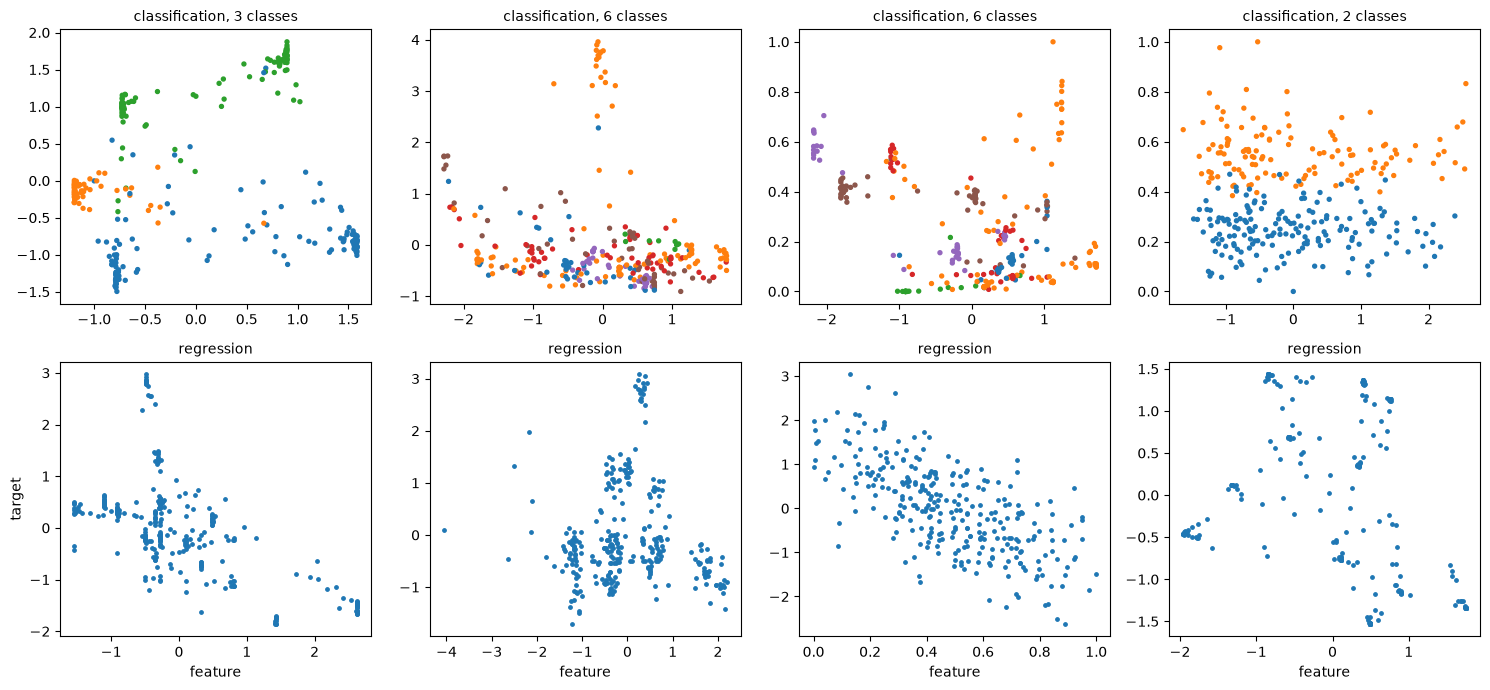

In [20]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

gen_rng = np.random.default_rng(10)
cv = KFold(3, shuffle=True, random_state=0)
shown_cls, shown_reg = [], []
while len(shown_cls) < 4:
    x, y = sample_dataset(gen_rng, "classification")
    continuous = all(len(np.unique(x[:, j])) > 20 for j in range(2))
    if np.isnan(x).any() or len(np.unique(y)) < 2 or not continuous:
        continue  # 그림이 잘 보이도록 결측값이 없고 앞의 두 feature가 연속값인 것만
    gain = cross_val_score(KNeighborsClassifier(15), x[:, :2], y, cv=cv).mean() - np.bincount(
        y
    ).max() / len(y)
    if gain > 0.2:
        shown_cls.append((x, y))
while len(shown_reg) < 4:
    x, y = sample_dataset(gen_rng, "regression", n_features=1)
    if np.isnan(x).any():
        continue
    if cross_val_score(KNeighborsRegressor(15), x, y, cv=cv).mean() > 0.3:
        shown_reg.append((x, y))

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (x, y) in zip(axes[0], shown_cls, strict=True):
    ax.scatter(x[:, 0], x[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=8)
    ax.set_title(f"classification, {len(np.unique(y))} classes", fontsize=10)
for ax, (x, y) in zip(axes[1], shown_reg, strict=True):
    ax.scatter(x[:, 0], y, s=6, color="C0")
    ax.set_title("regression", fontsize=10)
    ax.set_xlabel("feature")
axes[1, 0].set_ylabel("target")
plt.tight_layout()
plt.show()

점들이 몇 군데에 뭉친 덩어리(범주형 노드의 임베딩, 원형), 끊기거나 꺾인 관계(나무 간선, 계단·나머지 활성화), 곧은 줄무늬처럼 몇 개의 값에 몰린 feature(구간 나누기, Kumaraswamy 휘기) 같은 모양이 섞여 나옵니다. v1 prior의 데이터셋은 매끄러운 곡선 관계가 대부분이었습니다([`02_tabpfn/03`](../02_tabpfn/03_tabpfn_paper_walkthrough.ipynb) 3.2절의 그림).

결측값이 얼마나 자주 들어가는지, 무의미한 feature가 얼마나 생기는지도 세어 봅니다. 무의미한 feature는 "그 feature만으로 kNN이 target을 거의 못 맞힘"으로 어림합니다.

In [21]:
stats_rng = np.random.default_rng(11)
n_with_missing, useless, total = 0, 0, 0
for _ in range(200):
    x, y = sample_dataset(stats_rng, "classification")
    n_with_missing += np.isnan(x).any()
    if len(np.unique(y)) < 2 or np.isnan(x).any():
        continue
    base = np.bincount(y).max() / len(y)
    for j in range(x.shape[1]):
        acc = cross_val_score(KNeighborsClassifier(15), x[:, [j]], y, cv=cv).mean()
        useless += acc - base < 0.02
        total += 1
print(f"결측값이 있는 데이터셋: {n_with_missing / 200:.0%}")
print(f"혼자서는 target을 거의 못 맞히는 feature: {useless / total:.0%}")

결측값이 있는 데이터셋: 29%
혼자서는 target을 거의 못 맞히는 feature: 76%


데이터셋의 약 30%에 결측값이 있고, feature의 대부분은 혼자서는 target을 거의 맞히지 못합니다. 이 비율은 설명용으로 정한 분포에서 나온 값이라 논문 prior의 비율과는 다릅니다. 다만 target과 그래프에서 멀리 떨어진 노드가 많으면 쓸모없는 feature가 흔해진다는 점은 같습니다. feature 몇 개가 함께 있어야 target을 맞힐 수 있는 경우도 있으므로, "혼자서 쓸모없음"이 곧 "무의미함"은 아닙니다.

## 8. 이 prior가 가르치는 것

PFN은 prior에서 본 상황에만 대응하는 법을 배웁니다. 논문이 v2의 강점으로 보인 결과들은 prior의 구성 요소와 짝을 이룹니다.

| 실제 표의 어려움 | prior의 구성 요소 | 논문 결과 |
|---|---|---|
| 결측값 | MCAR 결측값 (6절) | 결측값이 있는 데이터셋에서도 상대 성능이 떨어지지 않음 (Fig. 5b) |
| 범주형 feature | 이산화한 노드, 구간 나누기 (3절, 6절) | 범주형 feature가 있어도 상대 성능 유지 (Fig. 5b) |
| 무의미한 feature | 다른 조각의 노드, 관계없는 위치의 노드 (2절, 5절) | 무의미한 feature를 더해도 강건함 (Fig. 5a). v1의 약점이었음 |
| 계단 모양 관계 | 결정 나무 간선, 계단 활성화 (3절) | toy 문제에서 계단 함수를 맞힘 (Fig. 3a) |
| 정규분포가 아닌 feature | Kumaraswamy 휘기, 다양한 활성화 (3절, 6절) | |
| 회귀 | 연속값 노드를 target으로 (5절) | 회귀 benchmark에서 튜닝한 baseline보다 좋음 (Fig. 4) |

## 9. 이 저장소가 쓰는 prior

논문의 prior를 그대로 재현할 수는 없습니다. 코드가 없고, 노드 수·$P$·간선 종류 비율·노이즈 크기 같은 수치가 논문에 없기 때문입니다. 이 노트북의 생성기도 절차만 따라 만든 것이고, 수치는 임의로 정했습니다.

그래서 이 저장소는 v2를 학습할 때 TabICL(Qu et al., ICML 2025)이 공개한 prior를 씁니다. TabICL은 v2와 같은 계열의 표 데이터 foundation model이고, prior 코드를 BSD-3 라이선스로 공개했습니다. MLP 모양 SCM, 결정 나무 SCM, 무작위 DAG를 쓰는 TabICLv2 graph prior를 고를 수 있고, 분류와 회귀 데이터셋을 모두 만듭니다. TabICLv2 graph prior는 GNR 대신 Cauchy 분포로 노드 사이의 연결 확률을 정하는 등 세부가 다릅니다. 어떤 점이 같고 다른지는 prior를 붙이는 단계에서 정리합니다.

## 10. 정리

| 단계 | 하는 일 | 이 노트북 |
|---|---|---|
| 그래프 | GNR로 scale-free 그래프를 뽑고, 조각을 합치기도 한다 | `sample_gnr_graph`, `merge_graphs` |
| 노드와 간선 | 노드는 벡터, 간선은 신경망·나무 함수 + 노이즈, 일부 노드는 이산화 | `make_nn_edge`, `make_tree_edge`, `propagate` |
| 초기 데이터 | 정규·균등·혼합, 원형으로 행끼리 닮게 | `sample_init`, `prototype_weights` |
| 읽기 | feature 노드와 target 노드의 값을 읽는다 (분류: 범주형 노드, 회귀: 연속값 노드) | `sample_dataset`의 3), 5) |
| 후처리 | Kumaraswamy 휘기, 구간 나누기, MCAR 결측값 | `kumaraswamy_warp`, `sample_dataset`의 6) |

다음 노트북 [`03_tabpfn_v2_paper_walkthrough`](03_tabpfn_v2_paper_walkthrough.ipynb)에서는 논문을 순서대로 읽으며 01과 02의 내용이 논문 어디에 해당하는지, 학습·추론·실험 결과는 어떤지 정리합니다.